# A7 long-term trends: is the season changing?

For each LGA, 1981 to 2025: April to October rain, rain start day and 10+ day dry spells (CHIRPS, through A2), and heat days (POWER). Each series is tested with Mann-Kendall and Sen's slope, against an ordinary least-squares baseline. Two guards keep the cards honest:

- **Autocorrelation:** the Hamed-Rao correction, used only when it makes the test stricter.
- **Many tests at once:** 23 LGAs x 4 series = 92 tests would give about 5 false "significant" trends at the 5 % level by chance alone, so Benjamini-Hochberg false discovery control sets the flag.

Formulas: `model/trends.py`. Settings: `config/models.yaml` (`trends`).

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import experiments
from model import trends as tr
from model.experiments import log_experiments
from model.io import write_csv
from model.settings import load_model_config

## 1. Build one annual series per LGA

In [4]:
# Build one annual series per LGA: season rain, rain start day and long dry spells from the
# LGA-year table, and heat days summed from complete POWER months (full years only).
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
t = cfg.trends
year = pd.read_parquet(cfg.paths.annual_features)
month = pd.read_parquet(cfg.paths.monthly_features)
complete = month[month["power_complete_month"].astype(bool)]
heat = complete.groupby(["lga", "year"]).agg(
    heat_days=("power_heat_days", "sum"), months=("month", "size")
)
heat = heat.loc[heat["months"] == 12, "heat_days"]
annual = (
    year[["lga", "year", "season_rain_mm", "a2_onset_doy", "a2_dry_spells_10plus"]]
    .rename(columns={"a2_onset_doy": "onset_doy", "a2_dry_spells_10plus": "dry_spells_10plus"})
    .join(heat, on=["lga", "year"])
)
annual = annual[annual["year"].between(t.years.start, t.years.end)]
annual[list(t.series)].count()

season_rain_mm       1035
onset_doy            1035
dry_spells_10plus    1035
heat_days            1035
dtype: int64

## 2. Test every LGA and series

In [5]:
# Test every LGA and series (23 x 4): Mann-Kendall p (and Hamed-Rao when stricter), Sen's
# slope, an OLS baseline, then Benjamini-Hochberg across all 92 tests.
table = tr.trend_table(annual, list(t.series), t.alpha)
table.groupby("series").agg(
    median_per_decade=("sen_slope_per_decade", "median"),
    lowest=("sen_slope_per_decade", "min"),
    highest=("sen_slope_per_decade", "max"),
    lgas_significant=("significant", "sum"),
    lgas_p_below_5pct_unadjusted=("trend_p", lambda p: int((p < 0.05).sum())),
    lgas_ols_p_below_5pct=("ols_p", lambda p: int((p < 0.05).sum())),
).round(2)

,median_per_decade,lowest,highest,lgas_significant,lgas_p_below_5pct_unadjusted,lgas_ols_p_below_5pct
series,,,,,,
dry_spells_10plus,0.00,0.00,0.00,0,3,3
heat_days,11.67,9.18,17.50,5,18,23
onset_doy,2.86,-2.13,5.64,0,3,5
season_rain_mm,2.94,-22.02,28.72,0,2,4


**Reading.** Heat days are rising everywhere (by about 9 to 17 days per decade), clearly so in a few LGAs. Rain start drifts later in most LGAs by about 3 days per decade, but after false discovery control no LGA's trend can be told apart from chance, and season rain and long dry spells show no trend. Cards should say so plainly rather than claim the season is shifting.

## 3. Is POWER's warming real? Check Tmax against ERA5-Land

In [6]:
# Cross-check POWER's warming against ERA5-Land Tmax with the same trend test.
tmax = month.groupby(["lga", "year"]).agg(
    power_tmax_c=("power_tmax_mean_c", "mean"),
    era5_tmax_c=("era5_tmax_c", "mean"),
    months=("era5_tmax_c", "count"),
)
tmax = tmax[tmax["months"] == 12].reset_index()
tmax = tmax[tmax["year"].between(t.years.start, t.years.end)]
check = tr.trend_table(tmax, ["power_tmax_c", "era5_tmax_c"], t.alpha)
check.groupby("series")[["sen_slope_per_decade", "significant"]].agg(["median", "sum"]).round(3)

sen_slope_per_decade         significant    
                           median     sum      median sum
series                                                   
era5_tmax_c                 0.223   5.388         1.0  23
power_tmax_c                0.497  11.611         1.0  23

Both datasets warm in every LGA, but POWER warms about twice as fast as ERA5-Land. The direction of the heat-day trend is solid; its size is probably overstated by POWER, and the card says "more heat days" rather than a number.

## 4. A worked example: Zaria's rain start, with both trend lines

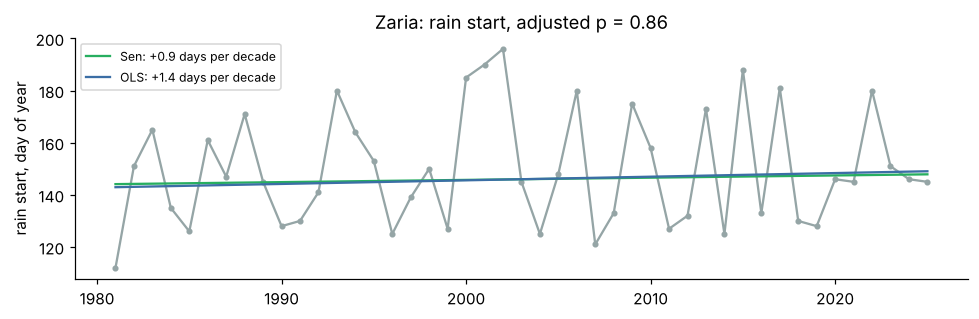

In [7]:
# Worked example: Zaria's rain start by year with the Sen and OLS lines.
lga = "Zaria"
series = annual[annual["lga"] == lga].dropna(subset=["onset_doy"])
row = table[(table["lga"] == lga) & (table["series"] == "onset_doy")].iloc[0]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(series["year"], series["onset_doy"], marker="o", ms=3, color="#95a5a6")
mid = series["year"].median()
for slope, colour, name in (
    (row["sen_slope_per_year"], "#27ae60", "Sen"),
    (row["ols_slope_per_year"], "#3b6ea5", "OLS"),
):
    ax.plot(
        series["year"],
        series["onset_doy"].median() + slope * (series["year"] - mid),
        color=colour,
        label=f"{name}: {slope * 10:+.1f} days per decade",
    )
ax.set_ylabel("rain start, day of year")
ax.set_title(f"{lga}: rain start, adjusted p = {row['p_adjusted']:.2f}")
ax.legend(fontsize=8)
plt.tight_layout()

## 5. Every LGA's trend, all four series

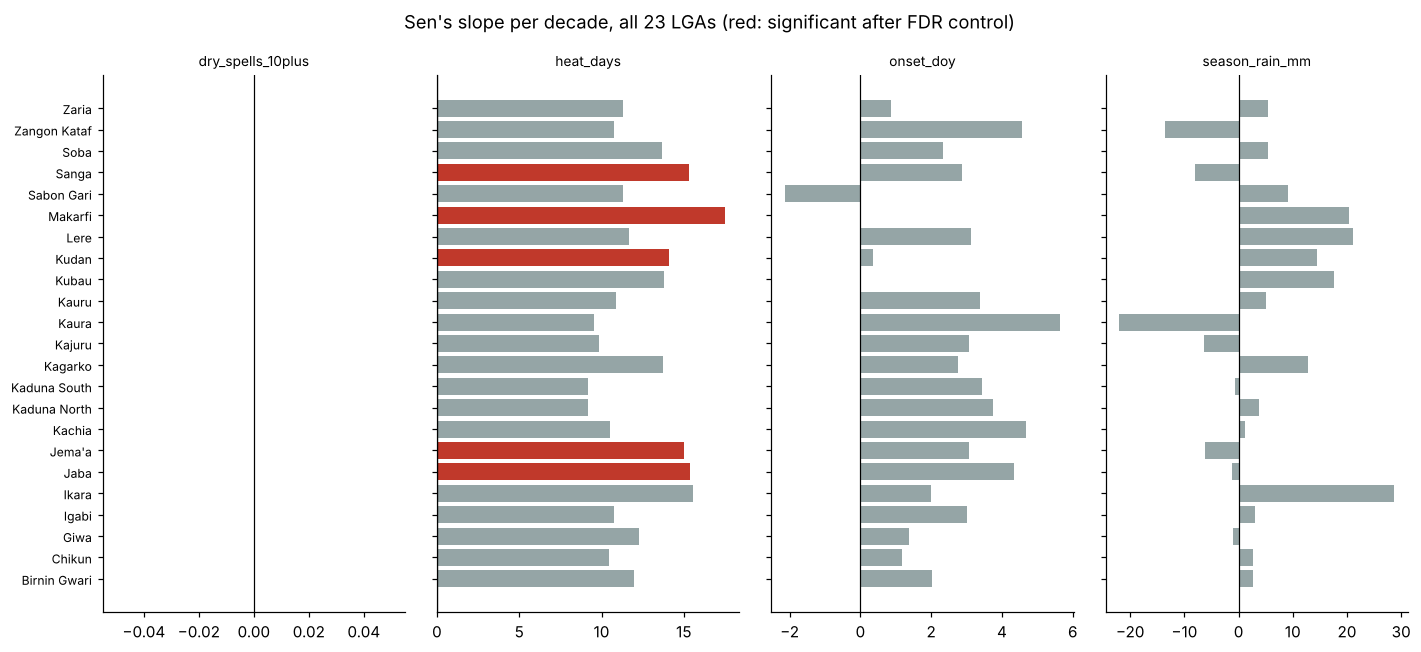

In [8]:
# All 23 LGAs: Sen's slope per decade for each series; red bars pass FDR control.
slopes = table.pivot(index="lga", columns="series", values="sen_slope_per_decade")
flags = table.pivot(index="lga", columns="series", values="significant")
fig, axes = plt.subplots(1, 4, figsize=(13, 6), sharey=True)
for ax, name in zip(axes, slopes.columns, strict=True):
    colour = flags[name].astype(bool).map({True: "#c0392b", False: "#95a5a6"})
    ax.barh(slopes.index, slopes[name], color=colour)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(name, fontsize=9)
axes[0].tick_params(axis="y", labelsize=8)
fig.suptitle("Sen's slope per decade, all 23 LGAs (red: significant after FDR control)")
plt.tight_layout()

## 6. Card lines for all 23 LGAs, and save

In [9]:
# Turn each result into the card's sentence ("no clear trend" unless significant), save
# the tables and log one row per series. The output is the card line for every LGA.
WORDS = {
    "season_rain_mm": ("Season rain", "mm", "more", "less"),
    "onset_doy": ("Rain start", "days", "later", "earlier"),
    "dry_spells_10plus": ("Long dry spells", "spells", "more", "fewer"),
    "heat_days": ("Heat days", "days", "more", "fewer"),
}
table["card_line"] = [
    tr.card_line(
        WORDS[r.series][0],
        r.sen_slope_per_decade,
        WORDS[r.series][1],
        r.significant,
        *WORDS[r.series][2:],
    )
    for r in table.itertuples()
]
out = cfg.paths.output_dir / "a7"
write_csv(table, out / "a7_lga_trends.csv")
write_csv(check, out / "a7_tmax_power_vs_era5.csv")
rows = [
    experiments.component_row(
        f"A7 Mann-Kendall + Sen: {name}",
        t.series[name],
        f"{t.years.start}-{t.years.end}, 23 LGAs",
        {
            "median_sen_per_decade": round(float(g["sen_slope_per_decade"].median()), 3),
            "lgas_significant_fdr": int(g["significant"].sum()),
        },
        "Hamed-Rao (stricter only) + Benjamini-Hochberg",
        experiments.today(),
    )
    for name, g in table.groupby("series")
]
log_experiments(cfg.paths.experiment_log, rows)
table.pivot(index="lga", columns="series", values="card_line")

series,dry_spells_10plus,heat_days,onset_doy,season_rain_mm
lga,,,,
Birnin Gwari,Long dry spells: 0 spells fewer per decade (no...,Heat days: 12 days more per decade (no clear t...,Rain start: 2 days later per decade (no clear ...,Season rain: 3 mm more per decade (no clear tr...
Chikun,Long dry spells: 0 spells fewer per decade (no...,Heat days: 10 days more per decade (no clear t...,Rain start: 1 days later per decade (no clear ...,Season rain: 3 mm more per decade (no clear tr...
Giwa,Long dry spells: 0 spells fewer per decade (no...,Heat days: 12 days more per decade (no clear t...,Rain start: 1 days later per decade (no clear ...,Season rain: 1 mm less per decade (no clear tr...
Igabi,Long dry spells: 0 spells fewer per decade (no...,Heat days: 11 days more per decade (no clear t...,Rain start: 3 days later per decade (no clear ...,Season rain: 3 mm more per decade (no clear tr...
Ikara,Long dry spells: 0 spells fewer per decade (no...,Heat days: 16 days more per decade (no clear t...,Rain start: 2 days later per decade (no clear ...,Season rain: 29 mm more per decade (no clear t...
Jaba,Long dry spells: 0 spells fewer per decade (no...,Heat days: 15 days more per decade (clear trend),Rain start: 4 days later per decade (no clear ...,Season rain: 1 mm less per decade (no clear tr...
Jema'a,Long dry spells: 0 spells fewer per decade (no...,Heat days: 15 days more per decade (clear trend),Rain start: 3 days later per decade (no clear ...,Season rain: 6 mm less per decade (no clear tr...
Kachia,Long dry spells: 0 spells fewer per decade (no...,Heat days: 11 days more per decade (no clear t...,Rain start: 5 days later per decade (no clear ...,Season rain: 1 mm more per decade (no clear tr...
Kaduna North,Long dry spells: 0 spells fewer per decade (no...,Heat days: 9 days more per decade (no clear tr...,Rain start: 4 days later per decade (no clear ...,Season rain: 4 mm more per decade (no clear tr...
